In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [62]:
df = pd.read_csv('form_responses.csv')
df.sort_values(by='Timestamp', inplace=True)

# Cleaning

Situazione iniziale

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 150 entries, 100 to 101
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Timestamp           150 non-null    object 
 1   age                 150 non-null    int64  
 2   sex                 150 non-null    object 
 3   weight              150 non-null    float64
 4   height              150 non-null    int64  
 5   train_years         150 non-null    object 
 6   train_week          150 non-null    int64  
 7   z2_train_week       148 non-null    float64
 8   fartelk_train_week  136 non-null    float64
 9   power_train_week    118 non-null    float64
 10  avg_km_week         150 non-null    object 
 11  sleep_hour          150 non-null    int64  
 12  vo2_max             150 non-null    object 
 13  min_heart_rate      150 non-null    int64  
 14  max_heart_rate      150 non-null    int64  
 15  cadence             141 non-null    object 
 16  hm_time    

In [64]:
print(f"Numero di righe: {df.shape[0]}")
print(f"Numero di colonne: {df.shape[1]}")

Numero di righe: 150
Numero di colonne: 18


In [65]:
df.head()

,Timestamp,age,sex,weight,height,train_years,train_week,z2_train_week,fartelk_train_week,power_train_week,avg_km_week,sleep_hour,vo2_max,min_heart_rate,max_heart_rate,cadence,hm_time,mid_hm_time
100,01/07/2025 00:07:41,18,Maschio,83.0,187,6,4,1.0,2.0,1.0,30,9,59,59,180,175,1:40:32,00:46:57
99,01/07/2025 00:41:15,27,Maschio,68.0,170,2,6,2.0,2.0,3.0,70,6,63,53,191,180,1:22:47,37:30
98,01/07/2025 08:48:29,23,Maschio,77.0,181,1,2,1.0,1.0,2.0,25,6,50,45,196,165,1:52:00,00:55:00
97,01/07/2025 10:11:15,28,Maschio,75.0,176,2,3,2.0,1.0,2.0,20,7,49,50,196,165,01:39:57,00:49:44
96,01/07/2025 11:59:10,27,Maschio,99.0,188,1,3,1.0,1.0,1.0,10,8,40,69,190,152,2:35:00,1:10:00


In [66]:
df.drop(columns=['Timestamp'], inplace=True)

In [67]:
df['sex'] = df['sex'].replace({'Femmina': 0, 'Maschio': 1})
df['sex'] = df['sex'].astype(int)

C:\Users\Gabri\AppData\Local\Temp\ipykernel_8056\160705813.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['sex'] = df['sex'].replace({'Femmina': 0, 'Maschio': 1})


In [68]:
df.train_years = df['train_years'].replace({'Meno di 1': 0.5 , '10 in su': 11})
df['train_years'] = df['train_years'].astype(float)

In [69]:
df.z2_train_week = df.z2_train_week.fillna(0).astype(int)
df.fartelk_train_week = df.fartelk_train_week.fillna(0).astype(int)
df.power_train_week = df.power_train_week.fillna(0).astype(int)

In [70]:
df['avg_km_week'] = df['avg_km_week'].replace({'Più di 80': 85})
df['avg_km_week'] = df['avg_km_week'].astype(int)

Creo la colonna per avere i tempi in secondi

In [71]:
def time_to_seconds(t):
    parts = t.split(':')
    parts = [int(p) for p in parts]
    if len(parts) == 3:
        h, m, s = parts
    elif len(parts) == 2:
        h = 0
        m, s = parts
    else:
        return None
    return h * 3600 + m * 60 + s

# Applica la funzione
df['hm_time_sec'] = df['hm_time'].apply(time_to_seconds)
df['mid_hm_time_sec'] = df['mid_hm_time'].apply(time_to_seconds)

Creo la colonna per avere i tempi in minuti

In [72]:
def time_to_minutes(t):
    parts = t.split(':')
    parts = [int(p) for p in parts]
    if len(parts) == 3:
        h, m, s = parts
    elif len(parts) == 2:
        h = 0
        m, s = parts
    else:
        return None
    return h * 60 + m + s / 60

df['hm_time_min'] = df['hm_time'].apply(time_to_minutes)
df['mid_hm_time_min'] = df['mid_hm_time'].apply(time_to_minutes)

df.drop(columns=['hm_time', 'mid_hm_time'], inplace=True)


Elimino outlier troppo grandi

In [73]:
df = df[df['hm_time_min'] < 140]

Colonne con troppi valori null

In [74]:
df_vo2_max = df.drop(columns=['cadence'])
df.drop(columns=['cadence', 'vo2_max'], inplace=True)

Controlliamo se ci sono valori null nel dataframe

In [75]:
df.replace(to_replace=r'[^0-9]+', value='', regex=True)
df_vo2_max.dropna(inplace=True)

df.isnull().values.any()

np.False_

Stampiamo i risultati della fase di cleaning

In [76]:
print(f"Numero di righe nel DataFrame: {len(df)}")
print(f"Numero di colonne nel DataFrame: {len(df.columns)}")

Numero di righe nel DataFrame: 145
Numero di colonne nel DataFrame: 17


**Controllo finale** 

In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 145 entries, 100 to 102
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age                 145 non-null    int64  
 1   sex                 145 non-null    int64  
 2   weight              145 non-null    float64
 3   height              145 non-null    int64  
 4   train_years         145 non-null    float64
 5   train_week          145 non-null    int64  
 6   z2_train_week       145 non-null    int64  
 7   fartelk_train_week  145 non-null    int64  
 8   power_train_week    145 non-null    int64  
 9   avg_km_week         145 non-null    int64  
 10  sleep_hour          145 non-null    int64  
 11  min_heart_rate      145 non-null    int64  
 12  max_heart_rate      145 non-null    int64  
 13  hm_time_sec         145 non-null    int64  
 14  mid_hm_time_sec     145 non-null    int64  
 15  hm_time_min         145 non-null    float64
 16  mid_hm_time

---

# EDA

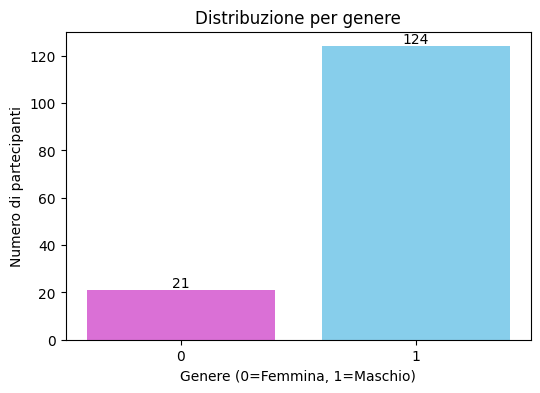

In [78]:
gender_counts = df['sex'].value_counts().sort_index()
plt.figure(figsize=(6, 4))
bars = plt.bar(gender_counts.index.astype(str), gender_counts.values, color=['orchid', 'skyblue'])
plt.xlabel('Genere (0=Femmina, 1=Maschio)')
plt.ylabel('Numero di partecipanti')
plt.title('Distribuzione per genere')

for bar in bars:
     height = bar.get_height()
     plt.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom')

plt.show()


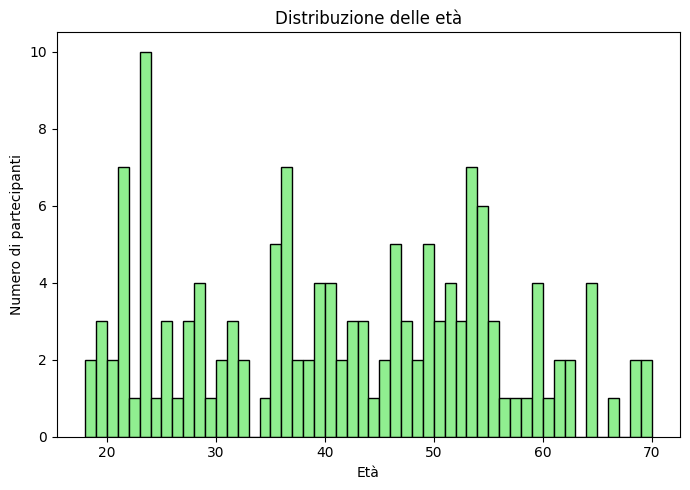

Età media: 41.57931034482758
Età mediana: 42.0
Età minima: 18
Età massima: 71
Deviazione standard dell'età: 14.367531376489357
age
18     2
19     3
20     2
21     7
22     1
23    10
24     1
25     3
26     1
27     3
28     4
29     1
30     2
31     3
32     2
34     1
35     5
36     7
37     2
38     2
39     4
40     4
41     2
42     3
43     3
44     1
45     2
46     5
47     3
48     2
49     5
50     3
51     4
52     3
53     7
54     6
55     3
56     1
57     1
58     1
59     4
60     1
61     2
62     2
64     4
66     1
68     2
70     2
71     2
Name: count, dtype: int64


In [79]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(df['age'], bins=range(df['age'].min(), df['age'].max()), color='lightgreen', edgecolor='black')
ax.set_xlabel('Età')
ax.set_ylabel('Numero di partecipanti')
ax.set_title('Distribuzione delle età')

plt.tight_layout()
plt.show()

print("Età media:", df['age'].mean())
print("Età mediana:", df['age'].median())
print("Età minima:", df['age'].min())
print("Età massima:", df['age'].max())
print("Deviazione standard dell'età:", df['age'].std())
print(df['age'].value_counts().sort_index())


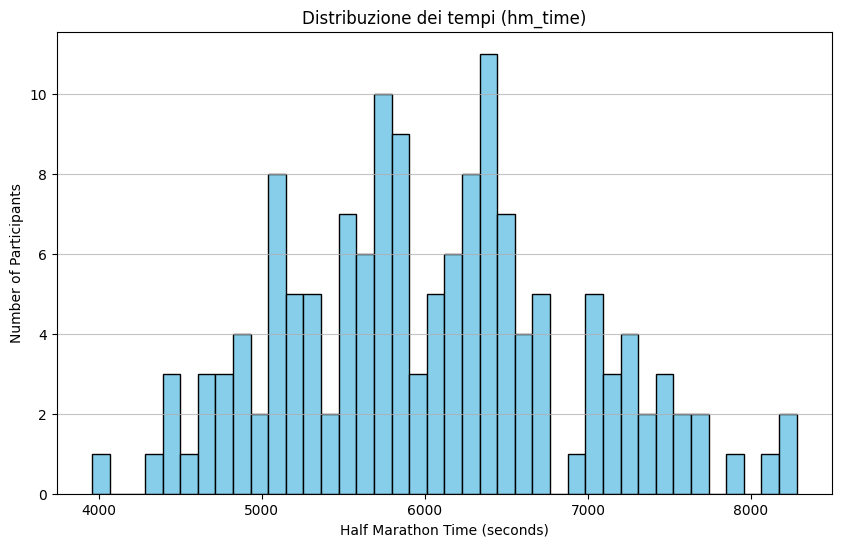

6029.896551724138
6000.0
3960
8280
885.2893729997894


In [80]:
hm_time_sec = df['hm_time_sec']
plt.figure(figsize=(10, 6))
plt.hist(hm_time_sec, bins=40, color='skyblue', edgecolor='black')
plt.xlabel('Half Marathon Time (seconds)')
plt.ylabel('Number of Participants')
plt.title('Distribuzione dei tempi (hm_time)')
plt.grid(axis='y', alpha=0.75)
plt.show()

print(hm_time_sec.mean())
print(hm_time_sec.median())
print(hm_time_sec.min())
print(hm_time_sec.max())
print(hm_time_sec.std())

Possiamo notare che la distribuzione dei tempi segue una distribuzione normale.

In [81]:
print("Tempo medio (min):", df.hm_time_min.mean())
print("Deviazione standard (min):", df.hm_time_min.std())

Tempo medio (min): 100.49827586206897
Deviazione standard (min): 14.75482288332982


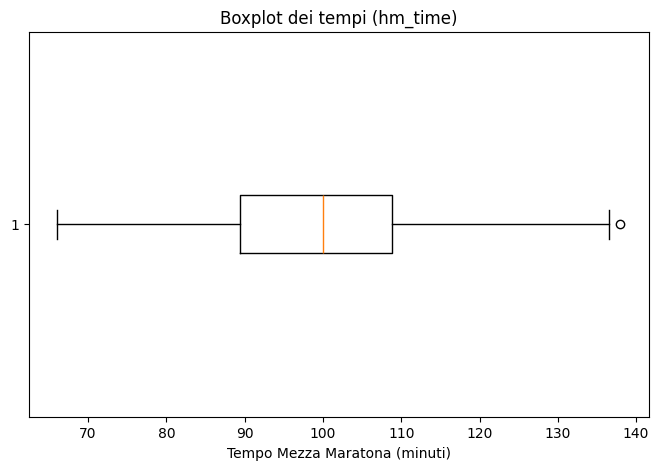

In [82]:
plt.figure(figsize=(8, 5))
plt.boxplot(df_vo2_max.hm_time_min, vert=False)
plt.xlabel('Tempo Mezza Maratona (minuti)')
plt.title('Boxplot dei tempi (hm_time)')
plt.show()

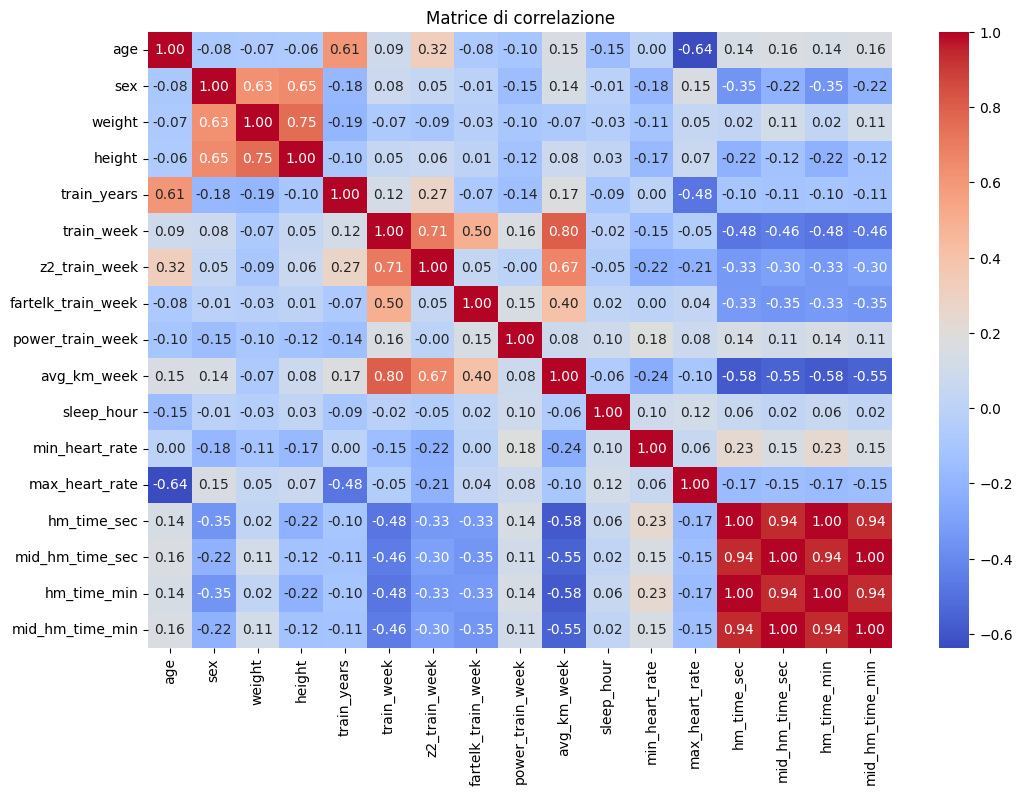

In [83]:

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", xticklabels=True, yticklabels=True)
plt.title("Matrice di correlazione")
plt.show()


Dalla matrice di correlazione emerge che i fattori più associati alla performance sono il chilometraggio medio settimanale e la frequenza degli allenamenti, oltre anche gli anni di esperienza. Le variabili fisiologiche, invece,  hanno correlazioni più deboli sul tempo finale.

### Z2 vs Power

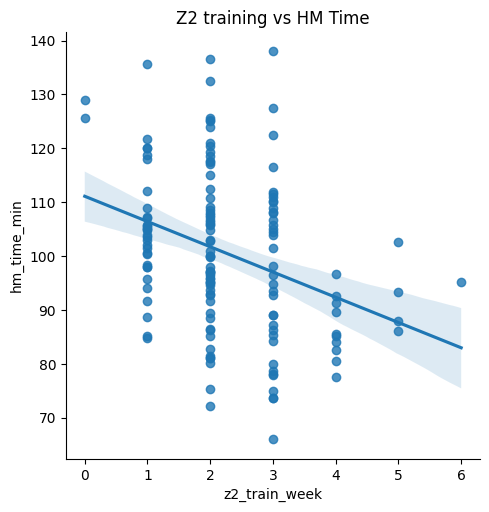

In [84]:
# Scatter plot + regressione
sns.lmplot(data=df, x='z2_train_week', y='hm_time_min')
plt.title("Z2 training vs HM Time")
plt.show()

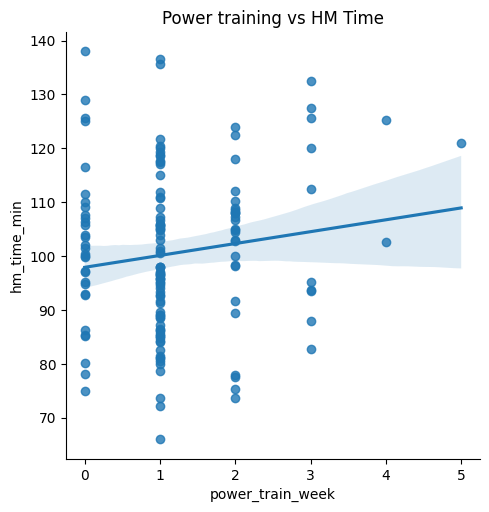

In [85]:
sns.lmplot(data=df, x='power_train_week', y='hm_time_min')
plt.title("Power training vs HM Time")
plt.show()

L'**indice di Pearson** permette di capire la forza e la direzione della correlazione tra due variabili quantitative

In [86]:
from scipy.stats import pearsonr

# Correlazioni Pearson
r_z2, _ = pearsonr(df['z2_train_week'], df['hm_time_min'])
r_power, _ = pearsonr(df['power_train_week'], df['hm_time_min'])

print(f"Correlazione Z2-HM Time: {r_z2:.2f}")
print(f"Correlazione Power-HM Time: {r_power:.2f}")

Correlazione Z2-HM Time: -0.33
Correlazione Power-HM Time: 0.14


Z2: La correlazione negativa indica che gli allenamenti in zona 2 sono associati a tempi finali migliori.

Power: La correlazione quasi nulla significa che gli allenamenti di potenza non hanno un’associazione chiara con il tempo finale in mezza maratona.

In [87]:
r_power10k, _ = pearsonr(df['power_train_week'], df['mid_hm_time_min'])
print(f"Correlazione Power vs Tempo 10km: {r_power10k:.2f}")

Correlazione Power vs Tempo 10km: 0.11


Idem per i primi 10km di gara, nessuna correlazione rilevante con gli allenamenti di potenza.

In [134]:
HM_KM = 21.097
FIRST10_KM = 10.0
SECOND_SEG_KM = HM_KM - FIRST10_KM  # 11.097 km

def min_decimal_to_mmss(m):
    mins = int(m)
    secs = round((m - mins) * 60)
    if secs == 60:
        mins += 1
        secs = 0
    return f"{mins}:{secs:02d}"

def fmt(m):  # "4.76 min/km (~4:46/km)"
    return f"{m:.2f} min/km (~{min_decimal_to_mmss(m)}/km)"

# Passo medio gara intera
df['passo_medio_km'] = df['hm_time_min'] / HM_KM

# Passo medio primi 10 km (tempo ufficiale 10k)
df['passo_primi_10km'] = df['mid_hm_time_min'] / FIRST10_KM

# Passo medio seconda parte (ultimi 11.097 km)
df['tempo_seconda_parte_min'] = df['hm_time_min'] - df['mid_hm_time_min']
df['passo_seconda_parte'] = df['tempo_seconda_parte_min'] / SECOND_SEG_KM

# Negative split rispetto ai 10 km: seconda parte più veloce della prima
df['negative_split_10k'] = df['passo_seconda_parte'] < df['passo_primi_10km']

num_negative_split = int(df['negative_split_10k'].sum())
totale_atleti = len(df)
percentuale = 100.0 * num_negative_split / totale_atleti if totale_atleti else 0.0

print("=== ANALISI PASSO MEZZA MARATONA (con 10 km come prima parte) ===\n")

print("Passo medio km (gara completa):")
print(f"  Media:   {fmt(df['passo_medio_km'].mean())}")
print(f"  Mediana: {fmt(df['passo_medio_km'].median())}\n")

print("Passo medio primi 10 km:")
print(f"  Media:   {fmt(df['passo_primi_10km'].mean())}")
print(f"  Mediana: {fmt(df['passo_primi_10km'].median())}\n")

print("Passo medio seconda parte (ultimi 11.097 km):")
print(f"  Media:   {fmt(df['passo_seconda_parte'].mean())}")
print(f"  Mediana: {fmt(df['passo_seconda_parte'].median())}\n")

print("=== NEGATIVE SPLIT (rispetto ai 10 km) ===")
print(f"Atleti con seconda parte più veloce: {num_negative_split} su {totale_atleti}")
print(f"Percentuale: {percentuale:.1f}%")

# (Facoltativo) Delta passo e controlli veloci
delta_s_km = (df['passo_seconda_parte'] - df['passo_primi_10km']) * 60
print(f"\nΔ passo medio (2^ - 1^, s/km): {delta_s_km.mean():.1f}  | mediano: {delta_s_km.median():.1f}")

# Controllo coerenza: 10k non può superare il tempo HM
invalid = (df['mid_hm_time_min'] > df['hm_time_min']).sum()
if invalid:
    print(f"\nATTENZIONE: {invalid} record hanno 10k_time > hm_time: verifica i dati.")


=== ANALISI PASSO MEZZA MARATONA (con 10 km come prima parte) ===

Passo medio km (gara completa):
  Media:   4.76 min/km (~4:46/km)
  Mediana: 4.74 min/km (~4:44/km)

Passo medio primi 10 km:
  Media:   4.70 min/km (~4:42/km)
  Mediana: 4.63 min/km (~4:38/km)

Passo medio seconda parte (ultimi 11.097 km):
  Media:   4.82 min/km (~4:49/km)
  Mediana: 4.83 min/km (~4:50/km)

=== NEGATIVE SPLIT (rispetto ai 10 km) ===
Atleti con seconda parte più veloce: 60 su 145
Percentuale: 41.4%

Δ passo medio (2^ - 1^, s/km): 7.0  | mediano: 4.6


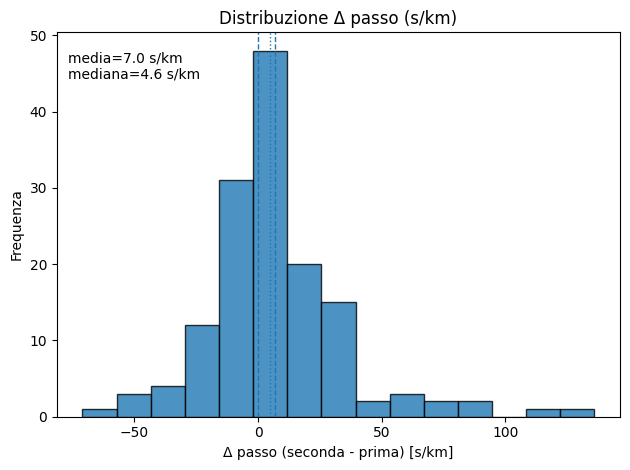

In [136]:


delta_s_km = (df["passo_seconda_parte"] - df["passo_primi_10km"]) * 60  # s/km
mean_d = delta_s_km.mean()
med_d  = delta_s_km.median()

plt.figure()
plt.hist(delta_s_km, bins=15, edgecolor="black", alpha=0.8)
plt.axvline(0, linestyle="--", linewidth=1)
plt.axvline(mean_d, linestyle="--", linewidth=1)
plt.axvline(med_d,  linestyle=":",  linewidth=1)
plt.xlabel("Δ passo (seconda - prima) [s/km]")
plt.ylabel("Frequenza")
plt.title("Distribuzione Δ passo (s/km)")
plt.text(0.02, 0.95, f"media={mean_d:.1f} s/km\nmediana={med_d:.1f} s/km", 
         transform=plt.gca().transAxes, va="top")
plt.tight_layout()
plt.show()


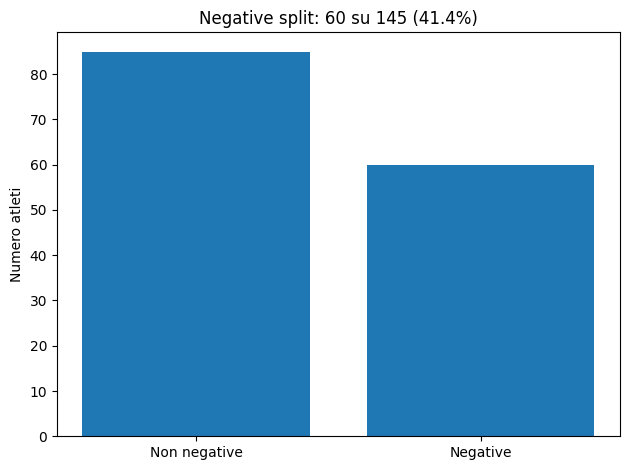

In [137]:

counts = df["passo_seconda_parte"].lt(df["passo_primi_10km"]).value_counts()
# Reordina per etichetta
labels = ["Non negative", "Negative"]
values = [counts.get(False, 0), counts.get(True, 0)]

plt.figure()
plt.bar(labels, values)
plt.ylabel("Numero atleti")
plt.title(f"Negative split: {values[1]} su {sum(values)} ({values[1]/sum(values)*100:.1f}%)")
plt.tight_layout()
plt.show()


In [140]:
HM_KM   = 21.097
HALF_KM = HM_KM / 2
FIRST10 = 10.0
SECOND  = HM_KM - FIRST10  # 11.097

# 1) Negative split usando i 10 km ufficiali (prima parte=10.0 km)
pace_10k      = df["mid_hm_time_sec"] / FIRST10
pace_second   = (df["hm_time_sec"] - df["mid_hm_time_sec"]) / SECOND
neg_10k       = (pace_second < pace_10k).mean()

# 2) Negative split sulla vera metà della stessa gara
pace_firsthalf  = df["mid_hm_time_sec"] / HALF_KM
pace_secondhalf = (df["hm_time_sec"] - df["mid_hm_time_sec"]) / HALF_KM
neg_true_half   = (pace_secondhalf < pace_firsthalf).mean()

print(f"Negative split vs 10 km: {100*neg_10k:.1f}%")
print(f"Negative split su metà reale: {100*neg_true_half:.1f}%")


Negative split vs 10 km: 41.4%
Negative split su metà reale: 4.8%


### Ore di sonno

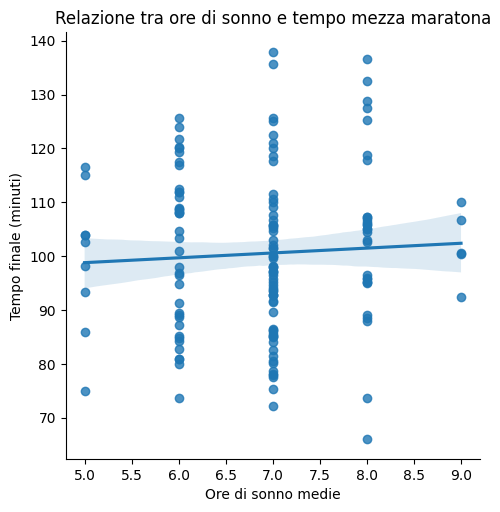

Coefficiente di correlazione: 0.055931507340495214


In [88]:
sns.lmplot(x='sleep_hour', y='hm_time_min', data=df)
plt.title('Relazione tra ore di sonno e tempo mezza maratona')
plt.xlabel('Ore di sonno medie')
plt.ylabel('Tempo finale (minuti)')
plt.show()

corr = df['sleep_hour'].corr(df['hm_time_min'])
print(f"Coefficiente di correlazione: {corr}")

Non c'è nessuna relazione diretta forte tra il sonno dell'atleta e il suo tempo finale in gara. 
Atleti con lo stesso sonno ottengono tempi molto diversi.

In [89]:
df.drop(columns=['sleep_hour'], inplace=True)

Possiamo quindi rimuovere la colonna, in modo da avere meno rumore successivamente nella fase di previsione.

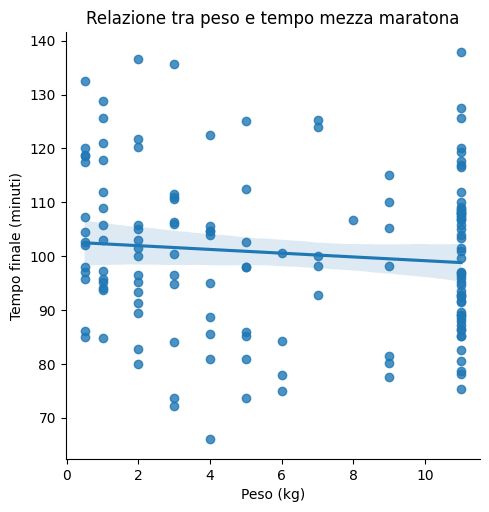

Coefficiente di correlazione: -0.10031800881623658


In [90]:
sns.lmplot(x='train_years', y='hm_time_min', data=df)
plt.title('Relazione tra peso e tempo mezza maratona')
plt.xlabel('Peso (kg)')
plt.ylabel('Tempo finale (minuti)')
plt.show()

corr = df['train_years'].corr(df['hm_time_min'])
print(f"Coefficiente di correlazione: {corr}")

### KDE - Density Plot (Group By Sex)

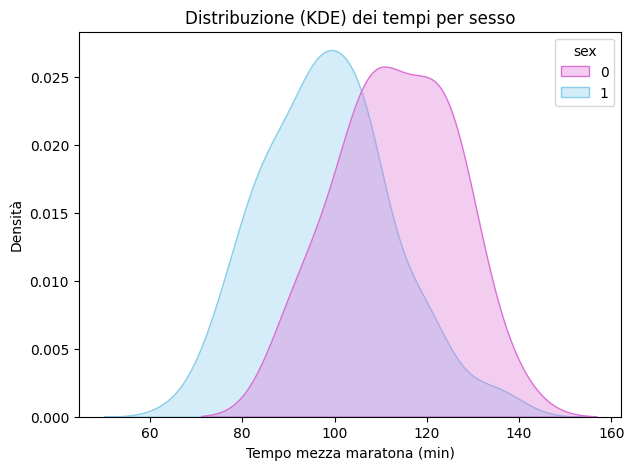

In [91]:
plt.figure(figsize=(7,5))
sns.kdeplot(
    data=df, x='hm_time_min', hue='sex',
    common_norm=False, fill=True, alpha=0.35,
    palette=['orchid', 'skyblue']
)
plt.title('Distribuzione (KDE) dei tempi per sesso')
plt.xlabel('Tempo mezza maratona (min)')
plt.ylabel('Densità')
plt.show()

###  Analisi per quartili

Prendiamo il primo (più veloci) e l'ultimo quartile (più lenti) per analizzarne le differenze.

In [92]:
q1 = df['hm_time_min'].quantile(0.25)
q3 = df['hm_time_min'].quantile(0.75)

# Creazione gruppi
df['quartile_group'] = pd.cut(
    df['hm_time_min'],
    bins=[df['hm_time_min'].min()-0.1, q1, q3, df['hm_time_min'].max()+0.1],
    labels=['Q1', 'Q2-Q3', 'Q4']
)

In [93]:
q1_df = df[df['quartile_group'] == 'Q1']
q4_df = df[df['quartile_group'] == 'Q4']

In [94]:
print("Q1 - Media Tempo Finale:", q1_df.hm_time_min.mean())
print("Q4 - Media Tempo Finale:", q4_df.hm_time_min.mean())

Q1 - Media Tempo Finale: 82.1990990990991
Q4 - Media Tempo Finale: 119.91388888888888


In [95]:
print("Q1 - Media km settimanali:", q1_df.avg_km_week.mean())
print("Q4 - Media km settimanali:", q4_df.avg_km_week.mean())


Q1 - Media km settimanali: 59.32432432432432
Q4 - Media km settimanali: 31.52777777777778


#### Numero allenamenti settimanali

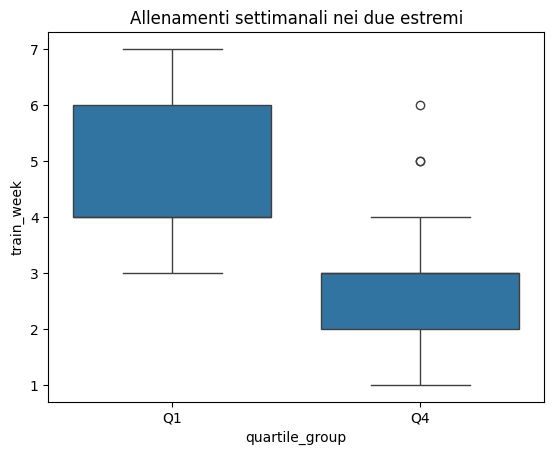

In [96]:
sns.boxplot(
    data=df[df['quartile_group'].isin(['Q1', 'Q4'])],
    x='quartile_group', y='train_week',
    order=['Q1', 'Q4']
)
plt.title('Allenamenti settimanali nei due estremi')
plt.show()

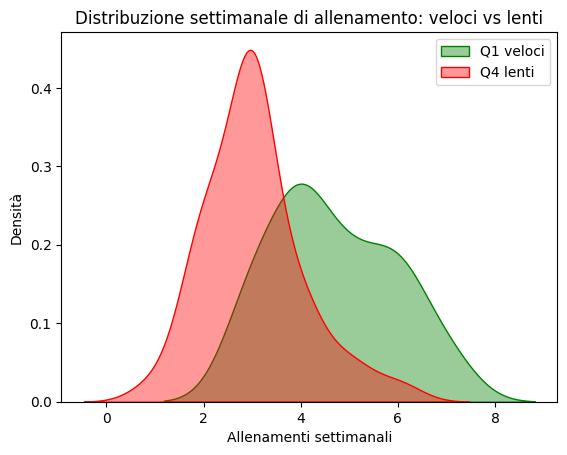

In [97]:
sns.kdeplot(data=q1_df, x='train_week', label='Q1 veloci', fill=True, alpha=0.4, color='green')
sns.kdeplot(data=q4_df, x='train_week', label='Q4 lenti', fill=True, alpha=0.4, color='red')

plt.title('Distribuzione settimanale di allenamento: veloci vs lenti')
plt.xlabel('Allenamenti settimanali')
plt.ylabel('Densità')
plt.legend()
plt.show()

#### Allenamenti di corsa Z2 settimanali

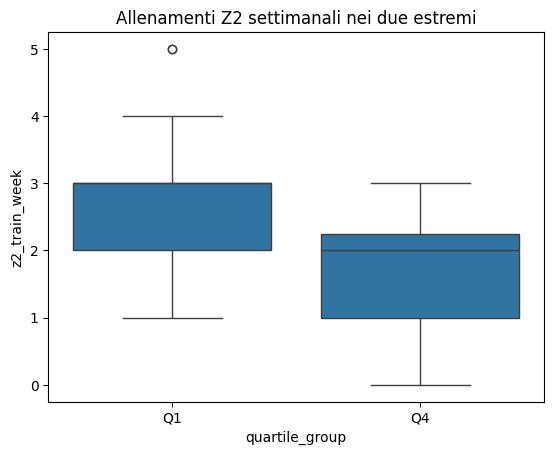

In [98]:
sns.boxplot(data=df[df['quartile_group'].isin(['Q1', 'Q4'])],
            x='quartile_group', y='z2_train_week', order=['Q1', 'Q4'])
plt.title('Allenamenti Z2 settimanali nei due estremi')
plt.show()

#### Allenamenti di potenza settimanali

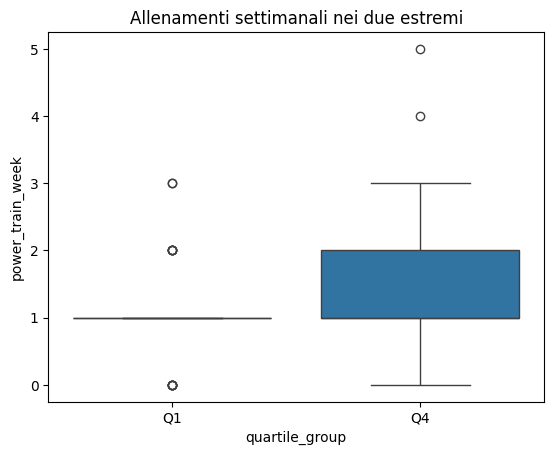

In [99]:
sns.boxplot(data=df[df['quartile_group'].isin(['Q1', 'Q4'])],
            x='quartile_group', y='power_train_week', order=['Q1', 'Q4'])
plt.title('Allenamenti settimanali nei due estremi')
plt.show()

Dal grafico si nota una differenza chiara nella frequenza di allenamento tra i due quartili presi in esame.
I runner più veloci mostrano una distribuzione centrata su 4–6 allenamenti settimanali, mentre i più lenti si concentrano intorno a 2 sedute settimanali. 
Il numero di allenamenti risulta quindi una variabile molto importante per la performance finale.

---

# Prevision

Essendo la variabile target continua, si utilizzerà l'indice R² per confrontare i vari modelli.

L'indice R² è una misura statistica che serve a valutare quanto bene un modello di regressione spiega la variabilità dei dati osservati.

Si calcola, sottraendo a 1, la somma dei quadrati dei residui (valore predetto - valore reale) diviso la somma dei quadrati totali (valore reale - valore medio).

## Splitting

In [100]:
from sklearn import model_selection

data_train, data_test = model_selection.train_test_split(df, test_size=0.2, random_state=42)

Il dataset è stato diviso con una percentuale dell'80% per il train e il restante 20% come test.

Avendo poche osservazioni, è stato deciso di non utilizzare il validation set in modo da avere più informazioni possibili nella fase di training.

In [101]:
# Train set
X_train = data_train[['age','sex','height','avg_km_week', 'train_years', 
                'train_week']]

y_train = data_train['hm_time_min']

print(X_train.columns)


# Test set
X_test = data_test[['age','sex','height','avg_km_week','train_years',
                  'train_week']]
y_test = data_test['hm_time_min']

Index(['age', 'sex', 'height', 'avg_km_week', 'train_years', 'train_week'], dtype='object')


In [102]:
rmse_results = []

## Linear Regression

LinearRegression fits a linear model with coefficients w = (w1, …, wp) to minimize the residual sum of squares between the observed targets in the dataset, and the targets predicted by the linear approximation.

Fonte: scikit-learn.org

In realtà, questa è una regressione multipla perchè ci sono più variabili indipendenti.

In [103]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rmse_results.append(("LinearRegression",rmse))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"R²   : {r2:.4f}")




MSE  : 64.69
RMSE : 8.04
MAE  : 6.79
R²   : 0.6730


## RBF

In [104]:
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Creazione modello SVM (kernel RBF di default)
svm_model = SVR(kernel='rbf', C=1000, gamma=0.001, epsilon=10)

# Addestramento
svm_model.fit(X_train, y_train)

# Predizioni
y_pred = svm_model.predict(X_test)

# Metriche
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rmse_results.append(("SVM_RBF",rmse))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} min")
print(f"MAE  : {mae:.2f} min")
print(f"R²   : {r2:.4f}")

MSE  : 165.80
RMSE : 12.88 min
MAE  : 9.94 min
R²   : 0.1619


## Pipeline con trasformazione e ricerca dei parametri ottimali su SVR (kernel RBF) 

Lo **Scaling** permette di normalizzare le feature. Molto utile in questo caso in cui le feature possono avere valori molto diversi. 

Esistono diversi tipi di scaling: RobustScaler, MinMaxScaler, StandardScaler, PowerTransformer

**GridSearchCV** è uno strumento che permette di trovare automaticamente i migliori iperparametri di un modello.

In [105]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer

pipe = make_pipeline(PowerTransformer(), SVR())

param_grid = {
    'svr__C': [1, 10, 100, 1000],
    'svr__gamma': [0.0001, 0.001, 0.01, 0.1, 'scale', 'auto'],
    'svr__epsilon': [0.1, 0.5, 1, 2]
}

grid = GridSearchCV(pipe, param_grid, scoring='neg_mean_squared_log_error', cv=10, n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print("Migliori parametri:", grid.best_params_)

y_pred = best_model.predict(X_test)



mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rmse_results.append(("SVM_RBF_Tuned",rmse))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} min")
print(f"MAE  : {mae:.2f} min")
print(f"R²   : {r2:.4f}")


Migliori parametri: {'svr__C': 10, 'svr__epsilon': 0.1, 'svr__gamma': 0.1}
MSE  : 111.12
RMSE : 10.54 min
MAE  : 8.02 min
R²   : 0.4383


## Random Forest

In [106]:
from sklearn.ensemble import RandomForestRegressor

# Modello Random Forest
rf_model = RandomForestRegressor(
    n_estimators=500,    # numero di alberi
    max_depth=5,      
    random_state=42,
    n_jobs=-1
)

# Addestramento
rf_model.fit(X_train, y_train)

# Predizioni
y_pred = rf_model.predict(X_test)

# Metriche
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rmse_results.append(("RandomForest",rmse))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} min")
print(f"MAE  : {mae:.2f} min")
print(f"R²   : {r2:.4f}")


MSE  : 103.65
RMSE : 10.18 min
MAE  : 7.75 min
R²   : 0.4761


## Gradient Boosting Regressor

In [107]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    n_estimators=10000,       # numero di alberi
    learning_rate=0.1,     # tasso di apprendimento
    max_depth=4,            # profondità massima
    subsample=0.6,          # percentuale di campioni usati per ogni albero
    random_state=42,
)

# Addestramento
gbr.fit(X_train, y_train)

# Predizioni
y_pred_gbr = gbr.predict(X_test)

# Metriche
mse_gbr = mean_squared_error(y_test, y_pred_gbr)
rmse_gbr = np.sqrt(mse_gbr)
rmse_results.append(("GradientBoosting",rmse_gbr))
mae_gbr = mean_absolute_error(y_test, y_pred_gbr)
r2_gbr = r2_score(y_test, y_pred_gbr)

print(f"[GBR] MSE  : {mse_gbr:.2f}")
print(f"[GBR] RMSE : {rmse_gbr:.2f} min")
print(f"[GBR] MAE  : {mae_gbr:.2f} min")
print(f"[GBR] R²   : {r2_gbr:.4f}")


[GBR] MSE  : 146.51
[GBR] RMSE : 12.10 min
[GBR] MAE  : 8.27 min
[GBR] R²   : 0.2594


## XGB - eXtreme Gradient Boosting

In [108]:
import xgboost as xgb

# Creazione modello XGBoost Regressor
xgb_model = xgb.XGBRegressor(
    n_estimators=10000,       # numero di alberi
    learning_rate=0.1,     # tasso di apprendimento
    max_depth=4,            # profondità massima
    subsample=0.6,          # percentuale di campioni usati per ogni albero
    colsample_bytree=0.6,   # percentuale di feature usate per ogni albero
    random_state=42,
    n_jobs=-1
)

# Addestramento
xgb_model.fit(X_train, y_train)

# Predizioni
y_pred = xgb_model.predict(X_test)

# Metriche
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rmse_results.append(("XGBoost",rmse))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"[XGBoost] MSE  : {mse:.2f}")
print(f"[XGBoost] RMSE : {rmse:.2f} min")
print(f"[XGBoost] MAE  : {mae:.2f} min")
print(f"[XGBoost] R²   : {r2:.4f}")

[XGBoost] MSE  : 141.71
[XGBoost] RMSE : 11.90 min
[XGBoost] MAE  : 8.51 min
[XGBoost] R²   : 0.2837


### Ridge / Lasso Regression

La regressione ridge, nota anche come regolarizzazione L2, è uno dei diversi tipi di regolarizzazione per i modelli di regressione lineare. La regolarizzazione è un metodo statistico per ridurre gli errori causati dall'overfitting dei dati di addestramento. La regressione ridge corregge specificamente la multicollinearità nell'analisi di regressione. Questo è utile quando si sviluppano modelli di machine learning con un numero elevato di parametri, in particolare se tali parametri hanno anche pesi elevati.

Fonte: IBM

In [109]:
# Ridge con scaling + CV su alpha
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import Pipeline

ridge_pipe = Pipeline([
    ("scaler", PowerTransformer()),
    ("ridge", RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5, scoring="neg_mean_squared_error"))
])

ridge_pipe.fit(X_train, y_train)
y_pred_ridge = ridge_pipe.predict(X_test)

mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
rmse_results.append(("Ridge",rmse_ridge))
mae_ridge  = mean_absolute_error(y_test, y_pred_ridge)
r2_ridge   = r2_score(y_test, y_pred_ridge)

best_alpha_ridge = ridge_pipe.named_steps["ridge"].alpha_
print(f"[Ridge] Best alpha: {best_alpha_ridge:.5f}")
print(f"[Ridge] MSE  : {mse_ridge:.2f}")
print(f"[Ridge] RMSE : {rmse_ridge:.2f} min")
print(f"[Ridge] MAE  : {mae_ridge:.2f} min")
print(f"[Ridge] R²   : {r2_ridge:.4f}")


[Ridge] Best alpha: 10.98541
[Ridge] MSE  : 66.47
[Ridge] RMSE : 8.15 min
[Ridge] MAE  : 6.82 min
[Ridge] R²   : 0.6640


La regressione lasso, nota anche come regolarizzazione L1, è una forma di regolarizzazione per i modelli di regressione lineare. La regolarizzazione è un metodo statistico per ridurre gli errori causati dall'overfitting dei dati di addestramento.

Fonte: IBM

In [110]:
from sklearn.linear_model import LassoCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer
import numpy as np

lasso_pipe = Pipeline([
    ("scaler", PowerTransformer()),
    ("lasso", LassoCV(alphas=np.logspace(-3, 3, 50),
                      cv=5, random_state=42, max_iter=10000))
])

lasso_pipe.fit(X_train, y_train)
y_pred_lasso = lasso_pipe.predict(X_test)

mse_lasso  = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
mae_lasso  = mean_absolute_error(y_test, y_pred_lasso)
r2_lasso   = r2_score(y_test, y_pred_lasso)

lasso = lasso_pipe.named_steps["lasso"]
best_alpha_lasso = lasso.alpha_

coef = lasso.coef_
kept    = np.array(feature_names)[coef != 0]
dropped = np.array(feature_names)[coef == 0]

print(f"[Lasso] Best alpha: {best_alpha_lasso:.5f}")
print(f"[Lasso] MSE  : {mse_lasso:.2f}")
print(f"[Lasso] RMSE : {rmse_lasso:.2f} min")
print(f"[Lasso] MAE  : {mae_lasso:.2f} min")
print(f"[Lasso] R²   : {r2_lasso:.4f}")
print(f"Feature attive: {np.count_nonzero(coef)} / {len(coef)}")
print("Tenute   :", kept)
print("Eliminate:", dropped)


NameError: name 'feature_names' is not defined

### ElasticNet

Linear Elastic Net utilizza la classe Python sklearn.linear_model.ElasticNet per stimare i modelli di regressione lineare regolarizzati per una variabile dipendente su una o più variabili indipendenti. 

La regolarizzazione combina le penalità L1 (Lasso) e L2 (Ridge). L'estensione include modalità facoltative per visualizzare i grafici di traccia per i diversi valori di alfa per un determinato rapporto L1 e per selezionare i valori del rapporto L1 e dell'iperparametro alfa in base alla convalida incrociata. 

Quando viene adattato un singolo modello o viene utilizzata la convalida incrociata per selezionare il rapporto di penalità e / o alfa, è possibile utilizzare una partizione di dati di holdout per stimare le prestazioni out - of - sample.

In [ ]:
# Elastic Net con scaling + CV su alpha e l1_ratio
from sklearn.linear_model import ElasticNetCV
from sklearn.pipeline import Pipeline


enet_pipe = Pipeline([
    ("scaler", PowerTransformer()),
    ("enet", ElasticNetCV(
        alphas=np.logspace(-3, 3, 50),
        l1_ratio=[0.2, 0.5, 0.8, 0.95, 1.0],
        cv=5, random_state=42, max_iter=10000
    ))
])

enet_pipe.fit(X_train, y_train)
y_pred_enet = enet_pipe.predict(X_test)


mse_enet = mean_squared_error(y_test, y_pred_enet)
rmse_enet = np.sqrt(mse_enet)
rmse_results.append(("ElasticNet",rmse_enet))
mae_enet  = mean_absolute_error(y_test, y_pred_enet)
r2_enet   = r2_score(y_test, y_pred_enet)



best_alpha_enet = enet_pipe.named_steps["enet"].alpha_
best_l1_ratio   = enet_pipe.named_steps["enet"].l1_ratio_
print(f"[ElasticNet] Best alpha: {best_alpha_enet:.5f} | Best l1_ratio: {best_l1_ratio}")
print(f"[ElasticNet] MSE  : {mse_enet:.2f}")
print(f"[ElasticNet] RMSE : {rmse_enet:.2f} min")
print(f"[ElasticNet] MAE  : {mae_enet:.2f} min")
print(f"[ElasticNet] R²   : {r2_enet:.4f}")


[ElasticNet] Best alpha: 0.49417 | Best l1_ratio: 1.0
[ElasticNet] MSE  : 69.31
[ElasticNet] RMSE : 8.33 min
[ElasticNet] MAE  : 6.92 min
[ElasticNet] R²   : 0.6497


### Gaussian Processes 

In [ ]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel


# Kernel: RBF + WhiteKernel per gestire rumore
kernel = 1.0 * RBF(length_scale=1.0) + WhiteKernel(noise_level=1e-2)

# Modello GPR
gpr = GaussianProcessRegressor(
    kernel=kernel,
    alpha=1e-2,              # niente rumore extra (già nel WhiteKernel)
    normalize_y=True,
    n_restarts_optimizer=5,
    random_state=42
)

# Addestramento
gpr.fit(X_train, y_train)

# Predizioni
y_pred = gpr.predict(X_test)

# Metriche
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rmse_results.append(("GPR",rmse))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"[GPR] MSE  : {mse:.2f}")
print(f"[GPR] RMSE : {rmse:.2f}")
print(f"[GPR] MAE  : {mae:.2f}")
print(f"[GPR] R²   : {r2:.4f}")

[GPR] MSE  : 101.98
[GPR] RMSE : 10.10
[GPR] MAE  : 7.80
[GPR] R²   : 0.4845


#### Confronto RMSE tra modelli

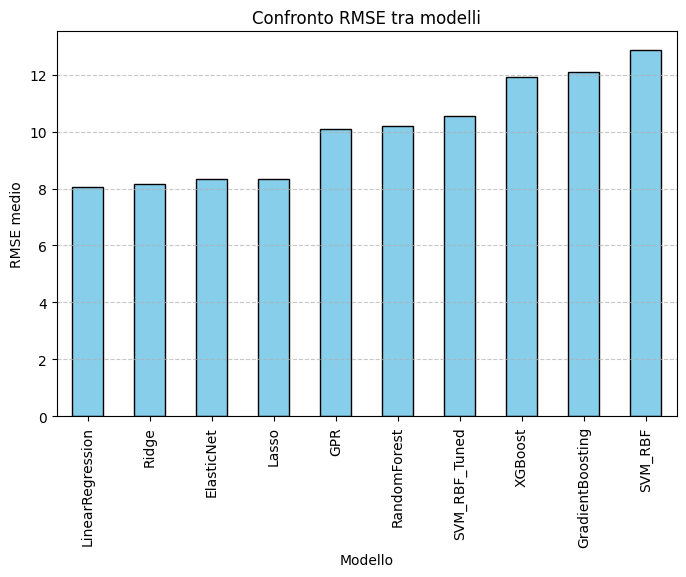

In [ ]:

# Trasforma la lista di tuple in DataFrame
df = pd.DataFrame(rmse_results, columns=["Modello", "RMSE"])

# Calcola la media degli RMSE per modello
rmse_mean = df.groupby("Modello")["RMSE"].mean().sort_values()

# Grafico a barre
plt.figure(figsize=(8, 5))
rmse_mean.plot(kind="bar", color="skyblue", edgecolor="black")

plt.ylabel("RMSE medio")
plt.title("Confronto RMSE tra modelli")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()


## Cross-Validation

In [ ]:
models = ["LinearRegression", "SVR_RBF","RandomForest" ,"Ridge"]
mean_rmse = []
std_rmse = []

#### LinearRegression

In [ ]:
from scipy import stats
from sklearn.model_selection import RepeatedKFold, cross_val_score

model = LinearRegression()

# 10-fold CV ripetuta 5 volte
cv = RepeatedKFold(n_splits=10, n_repeats=5, random_state=42)

scores = cross_val_score(model, X_train, y_train,
                         scoring="neg_root_mean_squared_error",
                         cv=cv)

rmse_values = -scores  # cross_val_score restituisce valori negativi


values = np.array(rmse_values)   # oppure acc_values, mae_values, ...
k = values.size
mean = values.mean()
se = stats.sem(values)              # = values.std(ddof=1)/np.sqrt(k)
tval = stats.t.ppf(0.975, df=k-1)   # 95%
ci = (mean - tval*se, mean + tval*se)

print("Ridge - Intervallo di confidenza al 95%:", ci)
print("RMSE per ogni fold:", rmse_values)
print("Media RMSE:", np.mean(rmse_values))
mean_rmse.append(np.mean(rmse_values))
print("Deviazione standard:", np.std(rmse_values, ddof=1))
std_rmse.append(np.std(rmse_values, ddof=1))


Ridge - Intervallo di confidenza al 95%: (np.float64(10.587108363120066), np.float64(12.024202506547041))
RMSE per ogni fold: [ 9.02265364 10.36336051 13.51577408 13.16411719 12.5768189   8.95742265
 14.76345241  7.37495674 14.80193436  7.77605056 13.34556432 12.90314466
  7.69245144 13.22968294  8.79302502 12.9121375  11.94516455 14.34274258
 11.38553983 11.38817871  7.66094462 11.30156202 11.51627962 14.78735439
  6.35284045 12.91228858  7.02911407  9.76240872 14.25442555 13.99543911
 10.33389515  9.37378486  7.76325872 14.46148163 12.30217028 15.27387251
  8.51459967  9.86455708 10.39901937 13.15048402 12.59070915  8.83988793
 11.13930281 12.30122548 14.85789056  8.01913046 12.11898511 12.12189053
  8.12354412 13.90625261]
Media RMSE: 11.305655434833554
Deviazione standard: 2.528342794152713


#### SVR - RBF

In [ ]:

# Modello SVR con kernel RBF (qui puoi mettere i tuoi parametri ottimizzati)
model = SVR(kernel="rbf", C=1000, gamma=0.001, epsilon=10)

# 10-fold CV ripetuta 5 volte
cv = RepeatedKFold(n_splits=10, n_repeats=5, random_state=42)

# cross_val_score restituisce valori negativi per convenzione (errori)
scores = cross_val_score(model, X_train, y_train,
                         scoring="neg_root_mean_squared_error",
                         cv=cv, n_jobs=-1)

# Invertiamo il segno → valori RMSE veri
rmse_values = -scores  

print("RMSE per ogni fold:", rmse_values)
print("Media RMSE:", np.mean(rmse_values))
mean_rmse.append(np.mean(rmse_values))
print("Deviazione standard:", np.std(rmse_values, ddof=1))
std_rmse.append(np.std(rmse_values, ddof=1))


RMSE per ogni fold: [12.12851693 10.56931292 18.12353349 18.4341065  15.14519733 13.90595249
 12.26058431 16.28703253 20.11676179 14.05628451 15.89285447 18.55209788
  6.95464743 18.27930988 13.49828468 20.11375208 13.13372523 13.9786524
 12.49867478 15.97128534 13.46793773 13.98696266  9.64619988 19.65156678
  8.28499821 14.66912584 13.31315    14.34441932 17.76274671 25.51154189
  9.6747446  12.41705763 11.5367985  15.31106063 15.67577171 19.61620003
  9.12432472 10.33271328 19.95246731 20.90746086 14.27338656 19.79949453
 17.95557465 14.77665495 12.34913965 14.23897352 15.90643457 13.88857556
  8.40699515 18.8723379 ]
Media RMSE: 14.911107645269333
Deviazione standard: 3.8355940350841355


In [ ]:
import scipy.stats as stats

rf_model = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

# Cross-validation ripetuta
cv = RepeatedKFold(n_splits=10, n_repeats=5, random_state=42)

scores = cross_val_score(rf_model, X_train, y_train,
                         scoring="neg_root_mean_squared_error",
                         cv=cv, n_jobs=-1)

rmse_values_rf = -scores




values = np.array(rmse_values_rf)   # oppure acc_values, mae_values, ...
k = values.size
mean = values.mean()
se = stats.sem(values)              # = values.std(ddof=1)/np.sqrt(k)
tval = stats.t.ppf(0.975, df=k-1)   # 95%
ci = (mean - tval*se, mean + tval*se)


print("Random Forest - RMSE per ogni fold:", rmse_values_rf)
print("Random Forest - RMSE medio:", np.mean(rmse_values_rf))
print("Random Forest - Intervallo di confidenza al 95%:", ci)
mean_rmse.append(np.mean(rmse_values_rf))
print("Random Forest - Dev std:", np.std(rmse_values_rf, ddof=1))
std_rmse.append(np.std(rmse_values_rf, ddof=1))

Random Forest - RMSE per ogni fold: [10.20759793  8.52064372 14.52854536  8.95217852 14.47311152  7.38679469
 12.62487529 10.09514108 17.65658183 10.00778229 11.06920593 10.27479312
  7.14060689 15.55403043 10.9427208  14.47326565 12.00367061 12.39669866
 10.77361194 14.9532227   7.80649392 12.58444226  8.89282997 18.22989507
  6.39078226 16.22928414  8.57305729  9.6438177  11.64814236 13.57350949
  9.6444464   8.87119948  8.16173157 14.90708248 11.25678126 15.08734044
  6.88960261  9.45051601 12.40299737 16.28698801 11.3663633  13.04650004
 15.00638806 14.77895756 10.91480724  7.62557496 13.77461813 11.33381335
  7.16328161 13.61748308]
Random Forest - RMSE medio: 11.583876127533808
Random Forest - Intervallo di confidenza al 95%: (np.float64(10.7216670769334), np.float64(12.446085178134215))
Random Forest - Dev std: 3.0338444424250954


In [ ]:
from sklearn.linear_model import Ridge

model = Ridge(alpha=1.0, random_state=42)

# 10-fold CV ripetuta 5 volte
cv = RepeatedKFold(n_splits=2, n_repeats=5, random_state=42)

# cross_val_score restituisce valori negativi (errore) → li invertiamo
scores = cross_val_score(model, X_train, y_train,
                         scoring="neg_root_mean_squared_error",
                         cv=cv, n_jobs=-1)

rmse_values = -scores

values = np.array(rmse_values)
k = values.size
mean = values.mean()
se = stats.sem(values)
tval = stats.t.ppf(0.975, df=k-1)   # 95%
ci = (mean - tval*se, mean + tval*se)

r2_scores = cross_val_score(rf_model, X_train, y_train,
                            scoring="r2",
                            cv=cv, n_jobs=-1)
r2_mean = r2_scores.mean()
r2_se = stats.sem(r2_scores)
r2_tval = stats.t.ppf(0.975, df=len(r2_scores)-1)
r2_ci = (r2_mean - r2_tval * r2_se, r2_mean + r2_tval * r2_se)


print("Ridge - Intervallo di confidenza al 95% (R2):", r2_ci)
print("Ridge - Media R2:", r2_mean)
print("Ridge - Deviazione standard R2:", np.std(r2_scores, ddof=1))
print("Ridge - R2 per ogni fold:", r2_scores)
print("------------------------------------------------------------------------")
print("Ridge - Intervallo di confidenza al 95% (RMSE):", ci)

print("RMSE per ogni fold:", rmse_values)
print("Media RMSE:", np.mean(rmse_values))
mean_rmse.append(np.mean(rmse_values))
print("Deviazione standard:", np.std(rmse_values, ddof=1))
std_rmse.append(np.std(rmse_values, ddof=1))

Ridge - Intervallo di confidenza al 95% (R2): (np.float64(0.28343256417384854), np.float64(0.37710981322990567))
Ridge - Media R2: 0.3302711887018771
Ridge - Deviazione standard R2: 0.06547588222876817
Ridge - R2 per ogni fold: [0.22987182 0.39012437 0.3590465  0.34110396 0.41419051 0.34061673
 0.38867225 0.26976319 0.23177412 0.33754842]
------------------------------------------------------------------------
Ridge - Intervallo di confidenza al 95% (RMSE): (np.float64(11.205508312450096), np.float64(12.220077098247938))
RMSE per ogni fold: [11.64900943 11.27848525 11.2046286  12.48748598 10.61533182 11.41242888
 11.19419036 11.98094423 12.84296118 12.46246133]
Media RMSE: 11.712792705349017
Deviazione standard: 0.7091346831943331


In [ ]:


from sklearn.model_selection import train_test_split


k = 5  # numero di ripetizioni (k >= 10, meglio 30 o 50)
alpha = 0.05  # livello di confidenza (95%)

results_stats = {}

print(data_train.columns)


for model_name, model in [("Linear Regression", LinearRegression()), 
                          ("Elastic Net", ElasticNetCV(alphas=np.logspace(-3, 3, 50),
        l1_ratio=[0.2, 0.5, 0.8, 0.95, 1.0],
        cv=5, random_state=42, max_iter=10000))]:
    
    r2_scores = []
    mse_scores = []
    
    for seed in range(k):
        # nuovo split casuale ogni volta
        data_train, data_test = model_selection.train_test_split(df, train_size=0.8, random_state=seed)

        X_train = data_train[['age','sex','height','avg_km_week', 'train_years', 
                'train_week','z2_train_week','fartelk_train_week','power_train_week']]

        y_train = data_train['hm_time_min']

        X_test = data_test[['age','sex','height','avg_km_week','train_years',
                  'train_week','z2_train_week', 'fartelk_train_week',
                  'power_train_week']]
        y_test = data_test['hm_time_min']
        
        # addestramento
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        # metriche
        r2_scores.append(r2_score(y_test, y_pred))
        mse_scores.append(mean_squared_error(y_test, y_pred))

    # conversione in array numpy
    r2_array = np.array(r2_scores)
    mse_array = np.array(mse_scores)
    
    # intervalli di confidenza
    conf_r2 = stats.t.interval(
        1 - alpha, len(r2_array)-1, loc=np.mean(r2_array), scale=stats.sem(r2_array)
    )
    conf_mse = stats.t.interval(
        1 - alpha, len(mse_array)-1, loc=np.mean(mse_array), scale=stats.sem(mse_array)
    )
    
    results_stats[model_name] = {
        "R2_mean": r2_array.mean(),
        "R2_std": r2_array.std(),
        "R2_conf": conf_r2,
        "MSE_mean": mse_array.mean(),
        "MSE_std": mse_array.std(),
        "MSE_conf": conf_mse,
        "R2_all": r2_array,
        "MSE_all": mse_array
    }
    
    # stampa riepilogo
    # Calcolo dell'RMSE
    rmse_array = np.sqrt(mse_array)

    # Stampa dei risultati
    print(f"\n=== {model_name} ===")
    print(f"R² medio: {r2_array.mean():.4f} ± {r2_array.std():.4f}")
    print(f"IC 95% R²: {conf_r2}")
    print(f"RMSE medio: {rmse_array.mean():.4f} ± {rmse_array.std():.4f}")  # RMSE invece di MSE
    print(f"IC 95% RMSE: {stats.t.interval(1 - alpha, len(rmse_array)-1, loc=rmse_array.mean(), scale=stats.sem(rmse_array))}")  # Intervallo di confidenza per RMSE


Index(['age', 'sex', 'weight', 'height', 'train_years', 'train_week',
       'z2_train_week', 'fartelk_train_week', 'power_train_week',
       'avg_km_week', 'min_heart_rate', 'max_heart_rate', 'hm_time_sec',
       'mid_hm_time_sec', 'hm_time_min', 'mid_hm_time_min', 'quartile_group'],
      dtype='object')


KeyError: "None of [Index(['age', 'sex', 'height', 'avg_km_week', 'train_years', 'train_week',\n       'z2_train_week', 'fartelk_train_week', 'power_train_week'],\n      dtype='object')] are in the [columns]"

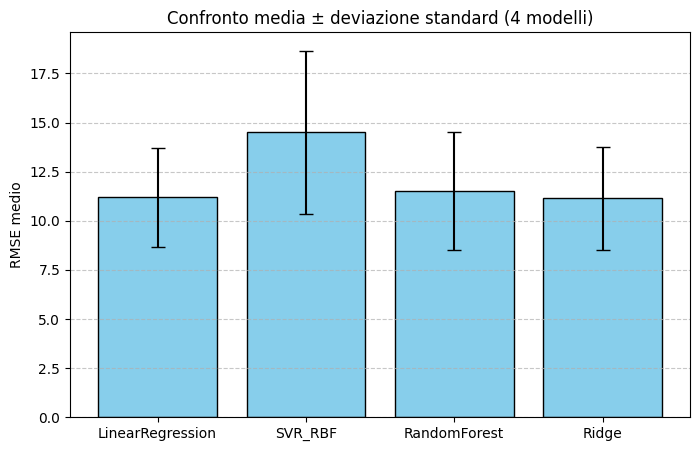

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(models, mean_rmse, yerr=std_rmse, capsize=5, color="skyblue", edgecolor="black")

plt.ylabel("RMSE medio")
plt.title("Confronto media ± deviazione standard (4 modelli)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

intervallo di confidenza

In [ ]:
from scipy import stats

k = len(df)
conf_interval = stats.t.interval(0.95, df=k-1, loc=np.mean(rmse_values), scale=stats.sem(rmse_values))
print("Intervallo di confidenza al 95%:", conf_interval)

Intervallo di confidenza al 95%: (np.float64(10.547093438522834), np.float64(11.731954912784685))


## Hyperparameter Tuning


--- Degree 1 ---
Migliori parametri: {'svr__C': 100, 'svr__epsilon': 0.1, 'svr__gamma': 'scale'}
RMSE=8.6766 | MAE=6.5361 | R2=0.6195

--- Degree 2 ---
Migliori parametri: {'svr__C': 10, 'svr__epsilon': 5, 'svr__gamma': 0.1}
RMSE=12.7015 | MAE=10.5309 | R2=0.1845

--- Degree 3 ---
Migliori parametri: {'svr__C': 1, 'svr__epsilon': 5, 'svr__gamma': 'scale'}
RMSE=11.3893 | MAE=9.5740 | R2=0.3443

--- Degree 4 ---
Migliori parametri: {'svr__C': 1, 'svr__epsilon': 1, 'svr__gamma': 'scale'}
RMSE=12.3940 | MAE=10.3484 | R2=0.2235

--- Degree 5 ---
Migliori parametri: {'svr__C': 1, 'svr__epsilon': 5, 'svr__gamma': 0.1}
RMSE=11.8889 | MAE=10.0116 | R2=0.2855


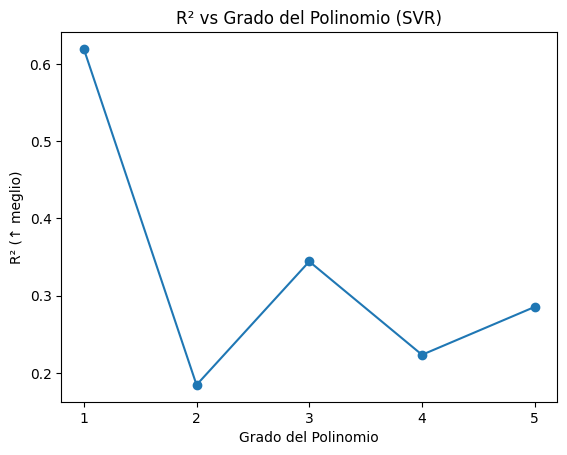

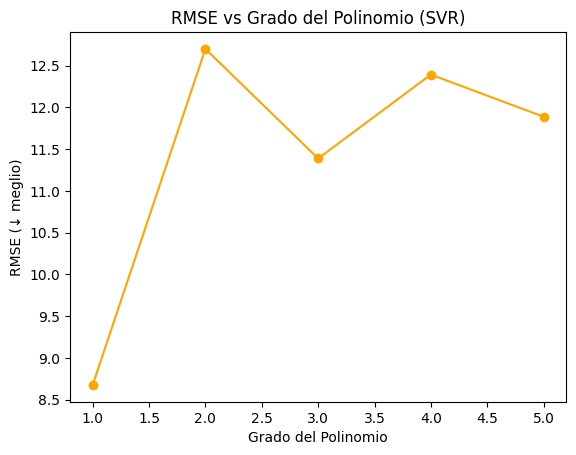

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn import svm

gradi = range(1, 6)
rmse_list, mae_list, r2_list = [], [], []

for d in gradi:
    print(f"\n--- Degree {d} ---")
    
    # Pipeline con scaling + SVR polinomiale
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", svm.SVR(kernel="poly", degree=d))
    ])
    
    # Griglia per C, epsilon e gamma
    param_grid = {
        "svr__C": [1, 10, 100],
        "svr__epsilon": [0.1, 1, 2, 5],
        "svr__gamma": [0.001, 0.01, 0.1, "scale"]
    }
    
    grid = GridSearchCV(pipe, param_grid, cv=5, scoring="r2", n_jobs=-1)
    grid.fit(X_train, y_train)
    
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)
    
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_test, y_pred)
    r2   = r2_score(y_test, y_pred)
    
    rmse_list.append(rmse)
    mae_list.append(mae)
    r2_list.append(r2)
    
    print("Migliori parametri:", grid.best_params_)
    print(f"RMSE={rmse:.4f} | MAE={mae:.4f} | R2={r2:.4f}")

# Grafici
plt.plot(gradi, r2_list, marker='o')
plt.title('R² vs Grado del Polinomio (SVR)')
plt.xlabel('Grado del Polinomio')
plt.ylabel('R² (↑ meglio)')
plt.xticks(gradi)
plt.show()

plt.plot(gradi, rmse_list, marker='o', color='orange')
plt.title('RMSE vs Grado del Polinomio (SVR)')
plt.xlabel('Grado del Polinomio')
plt.ylabel('RMSE (↓ meglio)')
plt.show()


Aumentando il grado del polinomio, il modello diventa sempre più flessibile e curvo, creando un andamento che non riflette la realtà, peggiorando le previsioni.
Per questo l'indice R2 diminuisce.